# 05 · Entrenamiento preliminar: línea base y ResNet18

> **Prototipo académico; no apto para diagnóstico ni decisiones clínicas.**

- **Solo se usan train y validación.** La prueba no se carga aquí.
- La mejor época de cada modelo se elige por **ROC-AUC en validación**.
- La salida es una **puntuación** entre 0 y 1, no una probabilidad clínica calibrada.
- Antes de ejecutar: *Entorno de ejecución → Cambiar tipo → GPU (T4)*.

In [1]:
# Montar Drive y fijar rutas (las mismas en todos los notebooks)
from google.colab import drive
drive.mount('/content/drive')

import os, sys
BASE    = "/content/drive/MyDrive/Aprendizaje final"
DATA    = f"{BASE}/Csv"
RES     = f"{BASE}/resultados"
SRC     = f"{BASE}/src"
PART    = f"{RES}/particiones"
PNG     = f"{BASE}/procesadas_224"     # recortes preprocesados (no van a Git)
MODELOS = f"{BASE}/modelos"            # checkpoints .pt (no van a Git)
for p in [DATA, RES, SRC, PART]:
    assert os.path.exists(p), f"No existe: {p}"
sys.path.insert(0, SRC)

Mounted at /content/drive


In [2]:
import time, datetime
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import modelo_utils as mu

SEMILLA = 42
BATCH   = 16
CONFIG = {   # una fila por modelo; cambia aquí, no dentro de las funciones
    "baseline": dict(epocas=30, lr=1e-3),
    "resnet18": dict(epocas=20, lr=1e-4),
}
FLIP, ROTACION = True, 10       # aumentos SOLO en entrenamiento

os.makedirs(MODELOS, exist_ok=True)
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
GPU = torch.cuda.get_device_name(0) if dispositivo == "cuda" else "CPU"
print("Dispositivo:", GPU, "| torch", torch.__version__)
print(open(f"{PNG}/config_preprocesamiento.txt").read())

Dispositivo: Tesla T4 | torch 2.14.1+cu130
ajuste=pad
tam=224
normalizacion=min-max por imagen
bits=8



In [3]:
train = pd.read_csv(f"{PART}/train.csv")
val   = pd.read_csv(f"{PART}/val.csv")
assert len(set(train.patient_id) & set(val.patient_id)) == 0, "Pacientes compartidos entre train y val"
for df_ in (train, val):
    assert all(os.path.exists(f"{PNG}/{l}.png") for l in df_.lesion_id), "Faltan PNG: ejecuta el notebook 04"
print("train:", len(train), "lesiones,", int(train.label.sum()), "malignas")
print("val:  ", len(val),   "lesiones,", int(val.label.sum()),   "malignas")

train: 146 lesiones, 64 malignas
val:   37 lesiones, 10 malignas


In [4]:
def ejecutar(nombre):
    cfg = CONFIG[nombre]
    mu.fijar_semilla(SEMILLA)
    dl_tr      = mu.crear_loader(train, PNG, True,  BATCH, SEMILLA, FLIP, ROTACION)
    dl_tr_eval = mu.crear_loader(train, PNG, False, BATCH, SEMILLA)
    dl_val     = mu.crear_loader(val,   PNG, False, BATCH, SEMILLA)
    modelo = mu.crear_modelo(nombre)
    print(f"\n=== {nombre} | parámetros entrenables: {mu.contar_parametros(modelo):,} ===")
    ckpt = f"{MODELOS}/{nombre}.pt"
    hist, mejor_ep, seg = mu.entrenar(modelo, dl_tr, dl_tr_eval, dl_val,
                                      cfg["epocas"], cfg["lr"], dispositivo, ckpt)
    hist.to_csv(f"{RES}/historial_{nombre}.csv", index=False)

    modelo.load_state_dict(torch.load(ckpt, map_location=dispositivo))
    pred, _ = mu.predecir(modelo.to(dispositivo), dl_val, dispositivo)
    pred = pred[["lesion_id", "patient_id", "label", "score"]]
    pred.to_csv(f"{RES}/pred_val_{nombre}.csv", index=False)

    auc, lo, hi = mu.auc_ic_bootstrap(pred)
    registro = dict(fecha=datetime.datetime.now().strftime("%Y-%m-%d %H:%M"), modelo=nombre,
                    semilla=SEMILLA, epocas=cfg["epocas"], mejor_epoca=mejor_ep, batch=BATCH,
                    optimizador="Adam", lr=cfg["lr"], aumentos=f"flip={FLIP}, rot={ROTACION}",
                    tiempo_s=round(seg, 1), gpu=GPU, auc_val=round(auc, 3),
                    auc_val_ic95=f"{lo:.2f}-{hi:.2f}")
    ruta_reg = f"{RES}/registro_experimentos.csv"
    pd.DataFrame([registro]).to_csv(ruta_reg, mode="a", index=False,
                                    header=not os.path.exists(ruta_reg))
    print(registro)
    return hist, pred

In [5]:
hist_base, pred_base = ejecutar("baseline")


=== baseline | parámetros entrenables: 98,049 ===
época   1 | loss train 0.695 val 0.709 | AUC train 0.550 val 0.578  <- mejor
época   2 | loss train 0.671 val 0.632 | AUC train 0.626 val 0.600  <- mejor
época   3 | loss train 0.662 val 0.590 | AUC train 0.698 val 0.648  <- mejor
época   4 | loss train 0.692 val 0.561 | AUC train 0.674 val 0.593
época   5 | loss train 0.642 val 0.739 | AUC train 0.685 val 0.611
época   6 | loss train 0.631 val 0.698 | AUC train 0.680 val 0.615
época   7 | loss train 0.711 val 0.554 | AUC train 0.686 val 0.593
época   8 | loss train 0.606 val 0.652 | AUC train 0.731 val 0.600
época   9 | loss train 0.724 val 0.967 | AUC train 0.672 val 0.541
época  10 | loss train 0.806 val 1.018 | AUC train 0.654 val 0.530
época  11 | loss train 0.626 val 0.607 | AUC train 0.708 val 0.648
época  12 | loss train 0.619 val 0.720 | AUC train 0.710 val 0.637
época  13 | loss train 0.617 val 0.607 | AUC train 0.726 val 0.622
época  14 | loss train 0.676 val 0.846 | AUC tra

In [6]:
hist_res, pred_res = ejecutar("resnet18")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 176MB/s]



=== resnet18 | parámetros entrenables: 11,177,025 ===
época   1 | loss train 0.672 val 0.611 | AUC train 0.667 val 0.493  <- mejor
época   2 | loss train 0.592 val 0.668 | AUC train 0.788 val 0.530  <- mejor
época   3 | loss train 0.532 val 0.567 | AUC train 0.919 val 0.663  <- mejor
época   4 | loss train 0.293 val 0.493 | AUC train 0.965 val 0.759  <- mejor
época   5 | loss train 0.257 val 0.612 | AUC train 0.972 val 0.774  <- mejor
época   6 | loss train 0.154 val 0.623 | AUC train 0.994 val 0.763
época   7 | loss train 0.142 val 0.659 | AUC train 0.988 val 0.763
época   8 | loss train 0.115 val 0.739 | AUC train 0.995 val 0.778  <- mejor
época   9 | loss train 0.082 val 0.543 | AUC train 0.997 val 0.819  <- mejor
época  10 | loss train 0.087 val 0.541 | AUC train 0.999 val 0.804
época  11 | loss train 0.058 val 0.701 | AUC train 0.999 val 0.815
época  12 | loss train 0.138 val 1.288 | AUC train 0.999 val 0.689
época  13 | loss train 0.041 val 1.141 | AUC train 1.000 val 0.674
époc

## Curvas de pérdida y AUC

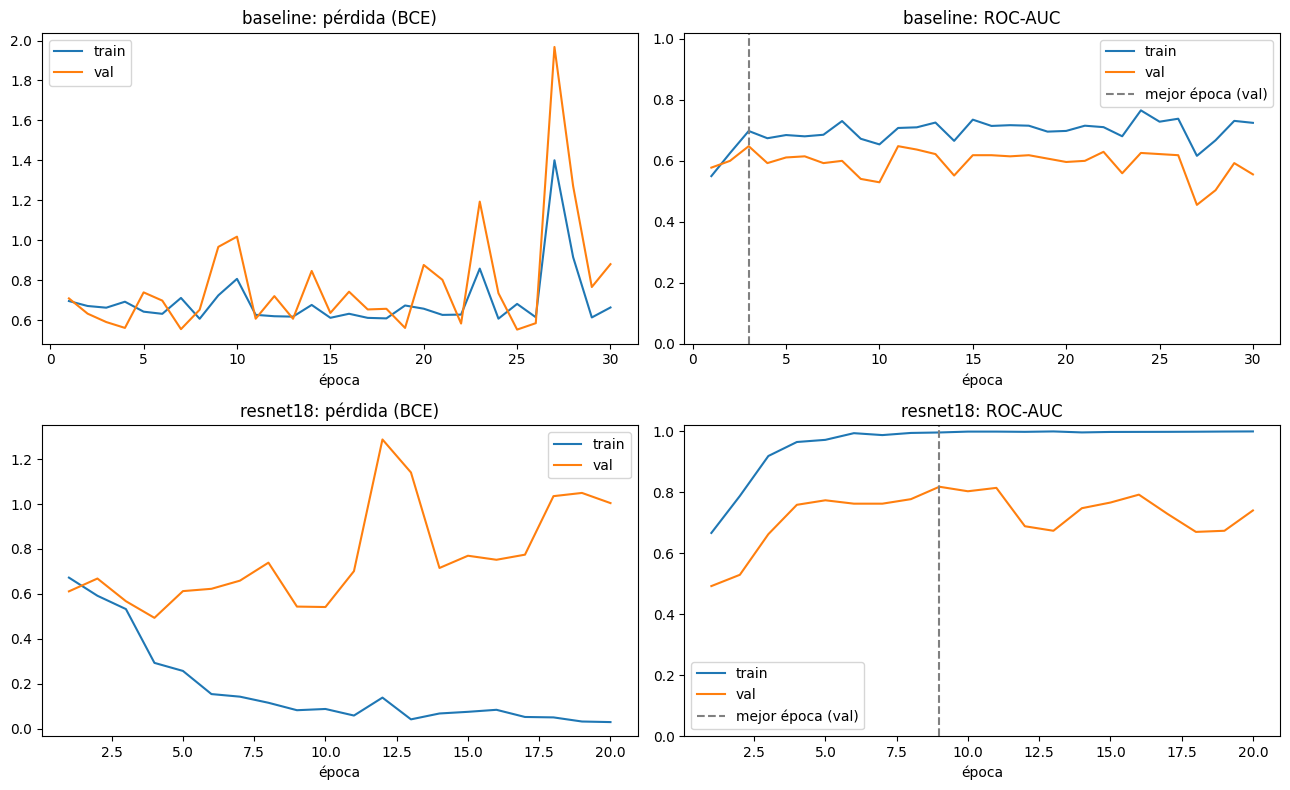

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for fila, (nom, h) in zip(ax, [("baseline", hist_base), ("resnet18", hist_res)]):
    fila[0].plot(h.epoca, h.loss_train, label="train"); fila[0].plot(h.epoca, h.loss_val, label="val")
    fila[0].set_title(f"{nom}: pérdida (BCE)"); fila[0].legend()
    fila[1].plot(h.epoca, h.auc_train, label="train"); fila[1].plot(h.epoca, h.auc_val, label="val")
    fila[1].axvline(h.auc_val.idxmax() + 1, ls="--", c="gray", label="mejor época (val)")
    fila[1].set_title(f"{nom}: ROC-AUC"); fila[1].set_ylim(0, 1.02); fila[1].legend()
    for a in fila: a.set_xlabel("época")
plt.tight_layout()
plt.savefig(f"{RES}/curvas_entrenamiento.png", dpi=110, bbox_inches="tight")
plt.show()

## Métricas en validación (umbral 0.5) e intervalos de confianza

In [8]:
filas = []
for nom, p in [("baseline", pred_base), ("resnet18", pred_res)]:
    auc, lo, hi = mu.auc_ic_bootstrap(p)
    filas.append(dict(modelo=nom, auc=round(auc, 3), auc_ic95=f"{lo:.2f}-{hi:.2f}",
                      **mu.metricas(p.label, p.score, 0.5)))
met = pd.DataFrame(filas).round(3)
met.to_csv(f"{RES}/metricas_val.csv", index=False)
met

,modelo,auc,auc_ic95,umbral,TP,FN,TN,FP,sensibilidad,sens_ic95,especificidad,esp_ic95,precision,f1
0,baseline,0.648,0.47-0.82,0.5,1,9,26,1,0.1,0.02-0.40,0.963,0.82-0.99,0.500,0.167
1,resnet18,0.819,0.63-0.99,0.5,6,4,19,8,0.6,0.31-0.83,0.704,0.52-0.84,0.429,0.500


## Efecto del umbral (solo validación)
Esto **muestra** el intercambio sensibilidad/especificidad (H2). La elección formal del umbral
es de los días 8-11 y se hará con validación, nunca con prueba.

In [9]:
for nom, p in [("baseline", pred_base), ("resnet18", pred_res)]:
    t = mu.tabla_umbrales(p, (0.5, 0.4, 0.3, 0.2)).round(3)
    t.to_csv(f"{RES}/umbrales_val_{nom}.csv", index=False)
    print(nom); display(t)

baseline


,umbral,TP,FN,TN,FP,sensibilidad,sens_ic95,especificidad,esp_ic95,precision,f1
0,0.5,1,9,26,1,0.1,0.02-0.40,0.963,0.82-0.99,0.500,0.167
1,0.4,3,7,21,6,0.3,0.11-0.60,0.778,0.59-0.89,0.333,0.316
2,0.3,10,0,1,26,1.0,0.72-1.00,0.037,0.01-0.18,0.278,0.435
3,0.2,10,0,0,27,1.0,0.72-1.00,0.000,0.00-0.12,0.270,0.426


resnet18


,umbral,TP,FN,TN,FP,sensibilidad,sens_ic95,especificidad,esp_ic95,precision,f1
0,0.5,6,4,19,8,0.6,0.31-0.83,0.704,0.52-0.84,0.429,0.500
1,0.4,6,4,19,8,0.6,0.31-0.83,0.704,0.52-0.84,0.429,0.500
2,0.3,7,3,18,9,0.7,0.40-0.89,0.667,0.48-0.81,0.438,0.538
3,0.2,8,2,17,10,0.8,0.49-0.94,0.630,0.44-0.78,0.444,0.571


## Matriz de confusión y errores del modelo ResNet18 (validación, umbral 0.5)

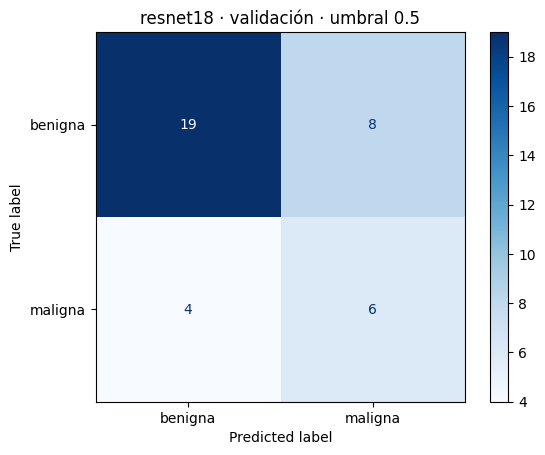

Falsos negativos:
         lesion_id patient_id  label    score  pred
 P_00198_LEFT_CC_1    P_00198      1 0.129288     0
P_00396_LEFT_MLO_1    P_00396      1 0.149555     0
P_00198_LEFT_MLO_1    P_00198      1 0.246195     0
P_00324_RIGHT_CC_1    P_00324      1 0.357272     0

Falsos positivos:
          lesion_id patient_id  label    score  pred
P_00173_RIGHT_MLO_1    P_00173      0 0.901671     1
  P_00429_LEFT_CC_1    P_00429      0 0.863895     1
P_00044_RIGHT_MLO_2    P_00044      0 0.845483     1
P_00032_RIGHT_MLO_1    P_00032      0 0.703415     1
 P_00429_LEFT_MLO_1    P_00429      0 0.695663     1
 P_00359_LEFT_MLO_1    P_00359      0 0.675792     1
 P_00044_RIGHT_CC_2    P_00044      0 0.543093     1
 P_00173_LEFT_MLO_1    P_00173      0 0.528971     1


In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
from PIL import Image
UMBRAL = 0.5
p = pred_res.assign(pred=(pred_res.score >= UMBRAL).astype(int))
ConfusionMatrixDisplay.from_predictions(p.label, p.pred, display_labels=["benigna", "maligna"],
                                        cmap="Blues")
plt.title(f"resnet18 · validación · umbral {UMBRAL}")
plt.savefig(f"{RES}/matriz_confusion_resnet18_val.png", dpi=110, bbox_inches="tight")
plt.show()

fn = p[(p.label == 1) & (p.pred == 0)].sort_values("score")
fp = p[(p.label == 0) & (p.pred == 1)].sort_values("score", ascending=False)
print("Falsos negativos:"); print(fn.to_string(index=False))
print("\nFalsos positivos:"); print(fp.to_string(index=False))

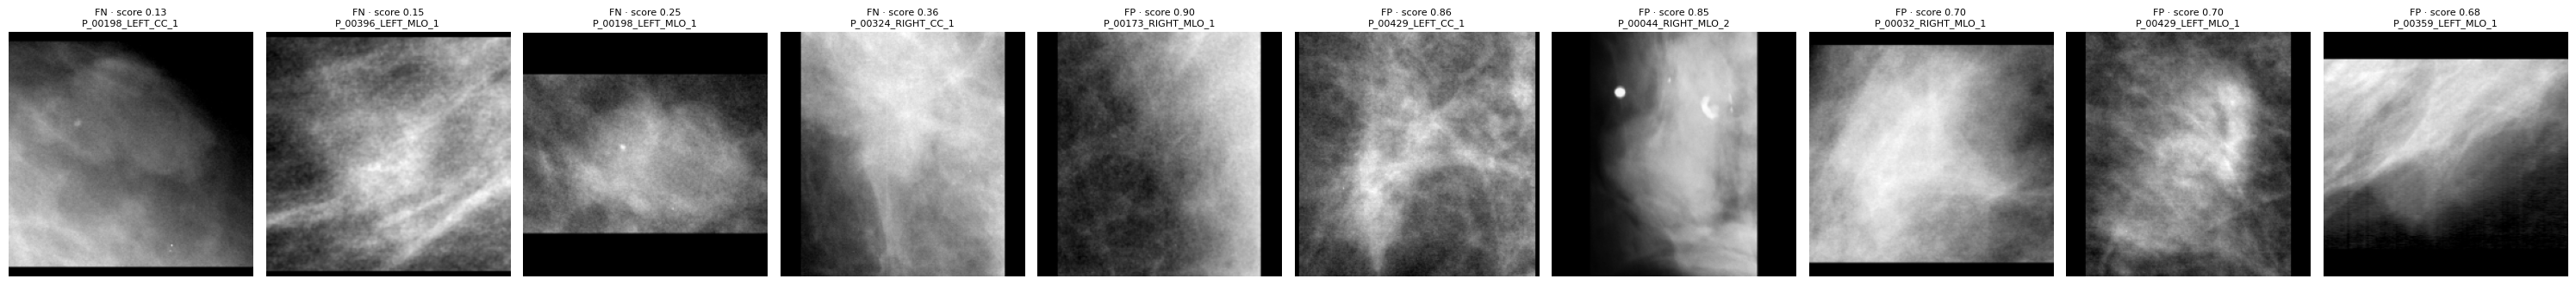

In [11]:
errores = pd.concat([fn.assign(tipo="FN"), fp.assign(tipo="FP")]).head(10)
if len(errores):
    fig, ax = plt.subplots(1, len(errores), figsize=(3 * len(errores), 3.6), squeeze=False)
    for a, r in zip(ax[0], errores.itertuples()):
        a.imshow(Image.open(f"{PNG}/{r.lesion_id}.png"), cmap="gray")
        a.set_title(f"{r.tipo} · score {r.score:.2f}\n{r.lesion_id}", fontsize=8); a.axis("off")
    plt.tight_layout()
    plt.savefig(f"{RES}/errores_resnet18_val.png", dpi=110, bbox_inches="tight")
    plt.show()

## Cómo leer los resultados (sin sobreinterpretar)
- **H1:** compara el AUC de validación de ambos modelos y mira si sus intervalos se solapan.
  Con 37 lesiones (10 malignas) una diferencia pequeña puede ser ruido.
- **H2:** en la fila de umbral 0.5, compara sensibilidad y especificidad; en la tabla de umbrales,
  mira si al bajar el umbral sube la sensibilidad y baja la especificidad.
- **Sobreajuste:** si el AUC de train llega a ~1 mientras el de validación se queda o baja,
  el modelo memoriza el entrenamiento.
- La validación tiene 27 % de malignas: la precisión depende de esa prevalencia;
  sensibilidad, especificidad y AUC no.